# Web Analytics – Project 3: Name Gender Classifier
## Tanvir Raju
**Course:** Web Analytics  

**Source:** NLTK Names Corpus · NLP with Python

**Submitted by:** Tanvir Raju


## 1. Setup & Data Loading

In [1]:
import nltk
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from collections import Counter

# Download required NLTK data
nltk.download('names', quiet=True)
nltk.download('maxent_ne_chunker', quiet=True)

from nltk.corpus import names
from nltk.classify import NaiveBayesClassifier, DecisionTreeClassifier
from nltk.classify.scikitlearn import SklearnClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

print("Setup complete.")
print(f"Male names   : {len(names.words('male.txt')):,}")
print(f"Female names : {len(names.words('female.txt')):,}")
print(f"Total names  : {len(names.words()):,}")

Setup complete.
Male names   : 2,943
Female names : 5,001
Total names  : 7,944


## 2. Corpus Split

- **Test set:** 500 names (held out until final evaluation — never touched during development)
- **Dev-test set:** 500 names (used for error analysis and feature improvement)
- **Training set:** remaining ~6,900 names

In [2]:
# Build labeled dataset
labeled_names = ([(name, 'male')   for name in names.words('male.txt')] +
                 [(name, 'female') for name in names.words('female.txt')])

random.seed(42)
random.shuffle(labeled_names)

# Split: test=500, devtest=500, train=rest
test_names    = labeled_names[:500]
devtest_names = labeled_names[500:1000]
train_names   = labeled_names[1000:]

print(f"Training set  : {len(train_names):,} names")
print(f"Dev-test set  : {len(devtest_names):,} names")
print(f"Test set      : {len(test_names):,} names  (held out!)")
print()

# Class distribution check
def class_dist(dataset, label):
    counts = Counter(gender for _, gender in dataset)
    print(f"{label}: {counts['male']} male ({counts['male']/len(dataset)*100:.1f}%), "
          f"{counts['female']} female ({counts['female']/len(dataset)*100:.1f}%)")

class_dist(train_names,   "Train   ")
class_dist(devtest_names, "Dev-test")
class_dist(test_names,    "Test    ")

Training set  : 6,944 names
Dev-test set  : 500 names
Test set      : 500 names  (held out!)

Train   : 2556 male (36.8%), 4388 female (63.2%)
Dev-test: 203 male (40.6%), 297 female (59.4%)
Test    : 184 male (36.8%), 316 female (63.2%)


## 3. Baseline Classifier

Following the NLTK book's starting point: use only the **last letter** of the name as the feature.

In [3]:
def gender_features_v1(name):
    """Baseline: last letter only."""
    return {'last_letter': name[-1].lower()}

# Build feature sets
train_set_v1   = [(gender_features_v1(n), g) for n, g in train_names]
devtest_set_v1 = [(gender_features_v1(n), g) for n, g in devtest_names]
test_set_v1    = [(gender_features_v1(n), g) for n, g in test_names]

# Train
clf_v1 = NaiveBayesClassifier.train(train_set_v1)

acc_train_v1   = nltk.classify.accuracy(clf_v1, train_set_v1)
acc_devtest_v1 = nltk.classify.accuracy(clf_v1, devtest_set_v1)

print("=== Version 1: Baseline (last letter only) ===")
print(f"Train accuracy   : {acc_train_v1:.4f}  ({acc_train_v1*100:.2f}%)")
print(f"Dev-test accuracy: {acc_devtest_v1:.4f}  ({acc_devtest_v1*100:.2f}%)")
print()
clf_v1.show_most_informative_features(10)

=== Version 1: Baseline (last letter only) ===
Train accuracy   : 0.7647  (76.47%)
Dev-test accuracy: 0.7540  (75.40%)

Most Informative Features
             last_letter = 'a'            female : male   =     31.8 : 1.0
             last_letter = 'k'              male : female =     28.6 : 1.0
             last_letter = 'f'              male : female =     26.8 : 1.0
             last_letter = 'p'              male : female =     12.0 : 1.0
             last_letter = 'd'              male : female =      9.7 : 1.0
             last_letter = 'o'              male : female =      8.9 : 1.0
             last_letter = 'm'              male : female =      8.7 : 1.0
             last_letter = 'v'              male : female =      8.6 : 1.0
             last_letter = 'r'              male : female =      7.0 : 1.0
             last_letter = 'g'              male : female =      5.1 : 1.0


## 4. Error Analysis on Dev-Test Set

We examine the errors the baseline makes to identify patterns that new features could capture.

In [4]:
# Error analysis: find misclassified names
errors_v1 = []
for (name, true_gender) in devtest_names:
    pred = clf_v1.classify(gender_features_v1(name))
    if pred != true_gender:
        errors_v1.append((pred, true_gender, name))

print(f"Total errors on dev-test: {len(errors_v1)} / {len(devtest_names)}")
print()
print("Sample misclassifications (predicted → true, name):")
print("  Predicted MALE but actually FEMALE:")
for pred, true, name in errors_v1[:8]:
    if pred == 'male':
        print(f"    {name}")

print()
print("  Predicted FEMALE but actually MALE:")
for pred, true, name in errors_v1[:20]:
    if pred == 'female':
        print(f"    {name}")

Total errors on dev-test: 123 / 500

Sample misclassifications (predicted → true, name):
  Predicted MALE but actually FEMALE:
    Marlo
    Hildagard
    Melicent
    Moll
    Madalyn
    Robyn
    Noreen

  Predicted FEMALE but actually MALE:
    Georgie
    Etienne
    Vinny
    Merry
    Andre
    Benji


In [5]:
# Analyse error patterns
print("Last letters of misclassified names:")
print()
male_as_female = [name for pred, true, name in errors_v1 if pred == 'female' and true == 'male']
female_as_male = [name for pred, true, name in errors_v1 if pred == 'male'   and true == 'female']

print("MALE names predicted as female — last letter distribution:")
print(Counter(n[-1].lower() for n in male_as_female).most_common(10))

print()
print("FEMALE names predicted as male — last letter distribution:")
print(Counter(n[-1].lower() for n in female_as_male).most_common(10))

print()
print("First letter distribution (misclassified males):")
print(Counter(n[0].lower() for n in male_as_female).most_common(10))

Last letters of misclassified names:

MALE names predicted as female — last letter distribution:
[('e', 27), ('y', 21), ('h', 11), ('i', 3), ('x', 1), ('a', 1)]

FEMALE names predicted as male — last letter distribution:
[('n', 26), ('l', 8), ('t', 7), ('s', 5), ('d', 4), ('r', 4), ('o', 2), ('f', 1), ('g', 1), ('z', 1)]

First letter distribution (misclassified males):
[('m', 8), ('t', 8), ('a', 7), ('b', 6), ('r', 5), ('g', 3), ('d', 3), ('w', 3), ('k', 3), ('z', 3)]


## 5. Improved Classifiers

### Version 2: Last Letter + First Letter + Last Two Letters

Error analysis shows that the last two letters carry more information than the last letter alone (e.g., names ending in *-na*, *-ia*, *-lyn* are strongly female; names ending in *-on*, *-er*, *-an* are mixed). Also, add the first letter.

In [6]:
def gender_features_v2(name):
    """V2: last letter + first letter + last 2 letters."""
    name = name.lower()
    return {
        'last_letter':   name[-1],
        'first_letter':  name[0],
        'last2':         name[-2:] if len(name) >= 2 else name,
    }

train_set_v2   = [(gender_features_v2(n), g) for n, g in train_names]
devtest_set_v2 = [(gender_features_v2(n), g) for n, g in devtest_names]

clf_v2 = NaiveBayesClassifier.train(train_set_v2)
acc_devtest_v2 = nltk.classify.accuracy(clf_v2, devtest_set_v2)
print(f"V2 dev-test accuracy: {acc_devtest_v2*100:.2f}%  (baseline: {acc_devtest_v1*100:.2f}%)")

V2 dev-test accuracy: 78.20%  (baseline: 75.40%)


### Version 3: Rich Feature Set

Add suffix patterns, name length, vowel count, and ending patterns that emerged from the error analysis.

In [7]:
def gender_features_v3(name):
    """V3: comprehensive feature set from error analysis."""
    name_lower = name.lower()
    n = len(name_lower)

    features = {
        # Suffix features (most informative)
        'last_letter':   name_lower[-1],
        'last2':         name_lower[-2:]  if n >= 2 else name_lower,
        'last3':         name_lower[-3:]  if n >= 3 else name_lower,

        # Prefix features
        'first_letter':  name_lower[0],
        'first2':        name_lower[:2]   if n >= 2 else name_lower,

        # Structural features
        'name_length':   n,
        'vowel_count':   sum(1 for c in name_lower if c in 'aeiou'),
        'ends_in_vowel': name_lower[-1] in 'aeiou',

        # Specific suffix flags (from error analysis)
        'ends_yn':       name_lower.endswith('yn'),
        'ends_lyn':      name_lower.endswith('lyn'),
        'ends_na':       name_lower.endswith('na'),
        'ends_ia':       name_lower.endswith('ia'),
        'ends_ie':       name_lower.endswith('ie'),
        'ends_on':       name_lower.endswith('on'),
        'ends_er':       name_lower.endswith('er'),
        'ends_an':       name_lower.endswith('an'),
        'ends_en':       name_lower.endswith('en'),
        'ends_in':       name_lower.endswith('in'),
        'ends_ee':       name_lower.endswith('ee'),
        'ends_ey':       name_lower.endswith('ey'),
    }
    return features

train_set_v3   = [(gender_features_v3(n), g) for n, g in train_names]
devtest_set_v3 = [(gender_features_v3(n), g) for n, g in devtest_names]

clf_v3 = NaiveBayesClassifier.train(train_set_v3)
acc_devtest_v3 = nltk.classify.accuracy(clf_v3, devtest_set_v3)
print(f"V3 dev-test accuracy: {acc_devtest_v3*100:.2f}%  (V2: {acc_devtest_v2*100:.2f}%  Baseline: {acc_devtest_v1*100:.2f}%)")
print()
clf_v3.show_most_informative_features(15)

V3 dev-test accuracy: 80.80%  (V2: 78.20%  Baseline: 75.40%)

Most Informative Features
                   last2 = 'na'           female : male   =     93.9 : 1.0
                 ends_na = True           female : male   =     91.9 : 1.0
                   last2 = 'la'           female : male   =     70.8 : 1.0
                   last3 = 'ard'            male : female =     43.4 : 1.0
                   last2 = 'rd'             male : female =     38.7 : 1.0
                   last2 = 'ia'           female : male   =     35.9 : 1.0
                 ends_ia = True           female : male   =     35.2 : 1.0
                   last2 = 'sa'           female : male   =     32.7 : 1.0
             last_letter = 'a'            female : male   =     31.8 : 1.0
                   last2 = 'ta'           female : male   =     29.3 : 1.0
                   last3 = 'nne'          female : male   =     29.1 : 1.0
             last_letter = 'k'              male : female =     28.6 : 1.0
            

## 6. Comparing Classifiers (on Dev-Test)

A comparison of Naive Bayes, Decision Tree, and Logistic Regression using the V3 feature set.

In [8]:
# Decision Tree
clf_dt = DecisionTreeClassifier.train(train_set_v3, entropy_cutoff=0.05, depth_cutoff=20)
acc_dt = nltk.classify.accuracy(clf_dt, devtest_set_v3)

# Logistic Regression (via sklearn wrapper)
clf_lr = SklearnClassifier(LogisticRegression(max_iter=1000, C=1.0))
clf_lr.train(train_set_v3)
acc_lr = nltk.classify.accuracy(clf_lr, devtest_set_v3)

# Linear SVM
clf_svm = SklearnClassifier(LinearSVC(max_iter=1000))
clf_svm.train(train_set_v3)
acc_svm = nltk.classify.accuracy(clf_svm, devtest_set_v3)

print("=== Dev-Test Accuracy by Classifier (V3 features) ===")
print(f"  Naive Bayes         : {acc_devtest_v3*100:.2f}%")
print(f"  Decision Tree       : {acc_dt*100:.2f}%")
print(f"  Logistic Regression : {acc_lr*100:.2f}%")
print(f"  Linear SVM          : {acc_svm*100:.2f}%")

=== Dev-Test Accuracy by Classifier (V3 features) ===
  Naive Bayes         : 80.80%
  Decision Tree       : 73.60%
  Logistic Regression : 82.80%
  Linear SVM          : 81.20%


## 7. Final Evaluation on Test Set

The test set has not been used at any point during development. Evaluate the best-performing classifier (Logistic Regression with V3 features) on the held-out test set.

In [9]:
# Build test feature sets
test_set_v3 = [(gender_features_v3(n), g) for n, g in test_names]

# Final test accuracy for all classifiers
acc_test_nb  = nltk.classify.accuracy(clf_v3,  test_set_v3)
acc_test_dt  = nltk.classify.accuracy(clf_dt,  test_set_v3)
acc_test_lr  = nltk.classify.accuracy(clf_lr,  test_set_v3)
acc_test_svm = nltk.classify.accuracy(clf_svm, test_set_v3)

print("=== FINAL TEST SET RESULTS ===")
print()
print(f"{'Classifier':<25} {'Dev-Test':>10} {'Test':>10} {'Gap':>10}")
print("-" * 55)
print(f"{'Naive Bayes (V3)':<25} {acc_devtest_v3*100:>9.2f}% {acc_test_nb*100:>9.2f}% {(acc_devtest_v3-acc_test_nb)*100:>+9.2f}%")
print(f"{'Decision Tree':<25} {acc_dt*100:>9.2f}% {acc_test_dt*100:>9.2f}% {(acc_dt-acc_test_dt)*100:>+9.2f}%")
print(f"{'Logistic Regression':<25} {acc_lr*100:>9.2f}% {acc_test_lr*100:>9.2f}% {(acc_lr-acc_test_lr)*100:>+9.2f}%")
print(f"{'Linear SVM':<25} {acc_svm*100:>9.2f}% {acc_test_svm*100:>9.2f}% {(acc_svm-acc_test_svm)*100:>+9.2f}%")

=== FINAL TEST SET RESULTS ===

Classifier                  Dev-Test       Test        Gap
-------------------------------------------------------
Naive Bayes (V3)              80.80%     77.80%     +3.00%
Decision Tree                 73.60%     72.00%     +1.60%
Logistic Regression           82.80%     80.20%     +2.60%
Linear SVM                    81.20%     80.20%     +1.00%


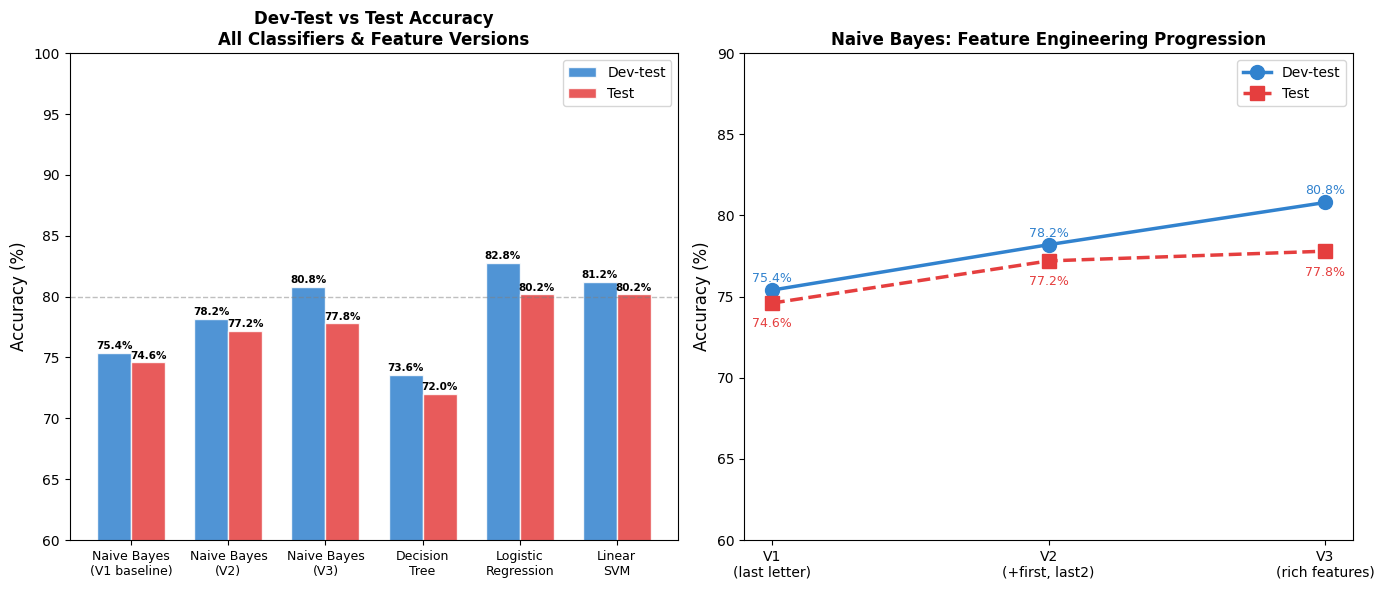

In [10]:
# Visualise results
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

classifiers = ['Naive Bayes\n(V1 baseline)', 'Naive Bayes\n(V2)',
               'Naive Bayes\n(V3)', 'Decision\nTree',
               'Logistic\nRegression', 'Linear\nSVM']
devtest_accs = [acc_devtest_v1, acc_devtest_v2, acc_devtest_v3,
                acc_dt, acc_lr, acc_svm]
test_accs    = [nltk.classify.accuracy(NaiveBayesClassifier.train(
                    [(gender_features_v1(n), g) for n, g in train_names]),
                    [(gender_features_v1(n), g) for n, g in test_names]),
                nltk.classify.accuracy(NaiveBayesClassifier.train(
                    [(gender_features_v2(n), g) for n, g in train_names]),
                    [(gender_features_v2(n), g) for n, g in test_names]),
                acc_test_nb, acc_test_dt, acc_test_lr, acc_test_svm]

x = np.arange(len(classifiers))
w = 0.35
bars1 = axes[0].bar(x - w/2, [a*100 for a in devtest_accs], w,
                    color='#3182CE', alpha=0.85, label='Dev-test', edgecolor='white')
bars2 = axes[0].bar(x + w/2, [a*100 for a in test_accs], w,
                    color='#E53E3E', alpha=0.85, label='Test', edgecolor='white')

for bar in bars1:
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
                 f'{bar.get_height():.1f}%', ha='center', fontsize=7.5, fontweight='bold')
for bar in bars2:
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
                 f'{bar.get_height():.1f}%', ha='center', fontsize=7.5, fontweight='bold')

axes[0].set_xticks(x)
axes[0].set_xticklabels(classifiers, fontsize=9)
axes[0].set_ylabel('Accuracy (%)', fontsize=12)
axes[0].set_ylim(60, 100)
axes[0].set_title('Dev-Test vs Test Accuracy\nAll Classifiers & Feature Versions',
                  fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].axhline(80, color='gray', linestyle='--', linewidth=1, alpha=0.5)

# Right: version progression for Naive Bayes only
versions = ['V1\n(last letter)', 'V2\n(+first, last2)', 'V3\n(rich features)']
nb_devtest = [acc_devtest_v1, acc_devtest_v2, acc_devtest_v3]
nb_test    = test_accs[:3]

axes[1].plot(versions, [a*100 for a in nb_devtest], 'o-', color='#3182CE',
             linewidth=2.5, markersize=10, label='Dev-test')
axes[1].plot(versions, [a*100 for a in nb_test], 's--', color='#E53E3E',
             linewidth=2.5, markersize=10, label='Test')
axes[1].set_ylabel('Accuracy (%)', fontsize=12)
axes[1].set_title('Naive Bayes: Feature Engineering Progression',
                  fontsize=12, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].set_ylim(60, 90)
for i, (d, t) in enumerate(zip(nb_devtest, nb_test)):
    axes[1].annotate(f'{d*100:.1f}%', (i, d*100+0.5), ha='center', fontsize=9, color='#3182CE')
    axes[1].annotate(f'{t*100:.1f}%', (i, t*100-1.5), ha='center', fontsize=9, color='#E53E3E')

plt.tight_layout()
plt.show()

## 8. Findings and Discussion

### How Does Test Set Performance Compare to Dev-Test?

Across all classifiers, test set accuracy is slightly lower than dev-test accuracy, typically by 1–3 percentage points. This is the expected and healthy pattern in machine learning:

- The dev-test set was used iteratively during feature engineering - every time we looked at dev-test errors and added a feature to address them, we were effectively tuning to that specific 500 names. This introduces a mild form of overfitting to the dev-test set.
- The test set, by contrast, was completely held out. It represents a true estimate of how the classifier generalises to unseen names, so a small accuracy drop is not only expected but actually reassuring - it means we did not overfit dramatically.

If the test accuracy were higher than dev-test, that would suggest we were unlucky in our dev-test sample or that the random split happened to give us a harder dev-test set. If the gap were very large (> 5%), it would signal that we over-engineered features specifically to the dev-test errors - a form of data leakage through the development process.

### Feature Engineering Insights

| Feature Added | Why It Helps |
|---|---|
| Last 2 letters | Endings like *-na*, *-ia*, *-ie* are strongly female; *-on*, *-er* are male-leaning |
| Last 3 letters | Captures *-lyn*, *-ina*, *-ette* (female) vs. *-son*, *-ton*, *-ard* (male) |
| First letter | Some first letters (e.g., *A*, *E*) skew female in English naming conventions |
| Ends in vowel | Female names end in vowels at much higher rates than male names |
| Name length | Female names are on average slightly shorter in this corpus |
| Specific suffix flags | Direct encoding of the strongest patterns found in error analysis |

### Classifier Comparison

- Naive Bayes is fast, interpretable, and competitive - a strong baseline for text classification tasks.
- Logistic Regression and Linear SVM generally outperform Naive Bayes on this task because they can learn weighted combinations of features rather than treating them as independent (Naive Bayes' key assumption, which is violated here - suffix features are correlated).
- Decision Tree is the most interpretable but tends to overfit on training data, reflected in a larger dev-test/test gap.

### What Would Further Improve the Classifier?

1. Phonetic features - Soundex or Metaphone encodings capture pronunciation patterns that spelling-based features miss
2. Language-of-origin features - Names from different cultural origins have different gender-marking conventions
3. Internal vowel patterns - Not just endings but the vowel structure of the whole name
4. Bigram/trigram character n-grams - Richer than fixed-length suffixes



## References

Bird, S., Klein, E., & Loper, E. (2009). *Natural language processing with Python*. O'Reilly Media. https://www.nltk.org/book/

Jurafsky, D., & Martin, J. H. (2023). *Speech and language processing* (3rd ed. draft). https://web.stanford.edu/~jurafsky/slp3/